# Machine Learning — Faktor-Faktor yang Berhubungan dengan Rata-rata Waktu Bermain Game di Steam
**Kelompok 8 — 3 TI B | Probabilitas dan Statistika 2026**

Dataset: Steam_games (Zenodo, CC BY 4.0) — https://zenodo.org/records/7904761

**Tujuan machine learning di projek ini:**
1. Membangun model regresi untuk **memprediksi rata-rata waktu bermain** sebuah game dari karakteristiknya (harga, achievement, jumlah pemilik, mode permainan, genre, dll).
2. Mengukur **faktor mana yang paling berpengaruh** terhadap rata-rata waktu bermain (feature importance) — ini yang menjawab inti judul "faktor-faktor yang berhubungan".
3. (Tambahan) Model klasifikasi untuk menebak **kategori waktu bermain** game: Rendah / Sedang / Tinggi.

> Model ML di sini melengkapi analisis statistika (deskriptif, distribusi, uji hipotesis), bukan menggantikannya.

## 1. Setup dan Load Data
Kalau pakai **Google Colab**: jalankan sel upload di bawah, lalu pilih file `3TIB_08_DataSteam.xlsx`.
Kalau pakai Jupyter lokal / Kaggle: cukup ubah `DATA_PATH` ke lokasi file.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, joblib
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             accuracy_score, classification_report, ConfusionMatrixDisplay)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

In [ ]:
# --- Khusus Google Colab: hapus tanda # di 2 baris bawah ini untuk upload file ---
# from google.colab import files
# files.upload()

DATA_PATH = '3TIB_08_DataSteam.xlsx'
df = pd.read_excel(DATA_PATH, sheet_name='Dataset')
print('Ukuran data:', df.shape)
df.head()

Ukuran data: (27075, 41)


,appid,nama_game,tahun_rilis,bahasa_inggris,batas_usia,harga_gbp,gratis,jumlah_achievement,punya_achievement,ulasan_positif,...,genre_strategy,genre_simulation,genre_rpg,genre_early_access,genre_free_to_play,genre_sports,genre_racing,jumlah_genre,developer,publisher
0,10,Counter-Strike,2000,1,0,7.19,0,0,0,124534,...,0,0,0,0,0,0,0,1,Valve,Valve
1,20,Team Fortress Classic,1999,1,0,3.99,0,0,0,3318,...,0,0,0,0,0,0,0,1,Valve,Valve
2,30,Day of Defeat,2003,1,0,3.99,0,0,0,3416,...,0,0,0,0,0,0,0,1,Valve,Valve
3,40,Deathmatch Classic,2001,1,0,3.99,0,0,0,1273,...,0,0,0,0,0,0,0,1,Valve,Valve
4,50,Half-Life: Opposing Force,1999,1,0,3.99,0,0,0,5250,...,0,0,0,0,0,0,0,1,Gearbox Software,Valve


## 2. Persiapan Data

**a. Filter game yang waktu bermainnya tercatat.**
Sebanyak ±77% game punya `rata_waktu_bermain_menit = 0`. Nilai 0 ini artinya **tidak tercatat** oleh SteamSpy (umumnya game dengan pemilik sangat sedikit), bukan berarti benar-benar tidak dimainkan. Kalau ikut dimasukkan, model hanya akan belajar "game sepi = 0 menit". Jadi untuk model dipakai `punya_waktu_bermain = 1`.

In [ ]:
print(df['punya_waktu_bermain'].value_counts().rename({1:'tercatat (>0)', 0:'tidak tercatat (0)'}))
print()
print('Proporsi game dengan waktu bermain tercatat per kode rentang pemilik:')
print(df.groupby('kode_rentang_pemilik')['punya_waktu_bermain'].mean().round(3))

data = df[df['punya_waktu_bermain'] == 1].copy()
print('\nData yang dipakai untuk model:', data.shape)

punya_waktu_bermain
tidak tercatat (0)    20905
tercatat (>0)          6170
Name: count, dtype: int64

Proporsi game dengan waktu bermain tercatat per kode rentang pemilik:
kode_rentang_pemilik
1     0.042
2     0.341
3     0.576
4     0.799
5     0.950
6     0.988
7     0.993
8     1.000
9     1.000
10    1.000
11    1.000
12    1.000
13    1.000
Name: punya_waktu_bermain, dtype: float64

Data yang dipakai untuk model: (6170, 41)


**b. Pilih kolom fitur.** Kolom yang **dibuang**:
- `appid`, `nama_game`, `developer`, `publisher` → identitas/teks, bukan karakteristik yang bisa digeneralisasi.
- `median_waktu_bermain_menit` → **kebocoran data (data leakage)**: korelasinya ±0,91 dengan target, ini sama saja "mencontek jawaban".
- `punya_waktu_bermain` → setelah difilter isinya 1 semua.
- `dukung_windows` → nilainya 1 semua (tidak memberi informasi).
- `rentang_pemilik` → sudah diwakili `kode_rentang_pemilik` (versi angka ordinal).
- `total_ulasan` → hasil penjumlahan ulasan positif + negatif (redundan).

In [ ]:
TARGET = 'rata_waktu_bermain_menit'
DROP = ['appid', 'nama_game', 'developer', 'publisher', 'median_waktu_bermain_menit',
        'punya_waktu_bermain', 'dukung_windows', 'rentang_pemilik', 'total_ulasan', TARGET]

X = data.drop(columns=DROP).copy()
print('Jumlah fitur:', X.shape[1])
print(list(X.columns))

Jumlah fitur: 31
['tahun_rilis', 'bahasa_inggris', 'batas_usia', 'harga_gbp', 'gratis', 'jumlah_achievement', 'punya_achievement', 'ulasan_positif', 'ulasan_negatif', 'persen_ulasan_positif', 'kode_rentang_pemilik', 'dukung_mac', 'dukung_linux', 'jumlah_platform', 'single_player', 'multi_player', 'steam_cloud', 'trading_cards', 'dukung_controller', 'genre_indie', 'genre_action', 'genre_casual', 'genre_adventure', 'genre_strategy', 'genre_simulation', 'genre_rpg', 'genre_early_access', 'genre_free_to_play', 'genre_sports', 'genre_racing', 'jumlah_genre']


## 3. Melihat Target: Kenapa Perlu Transformasi Log
Rata-rata waktu bermain **sangat menceng kanan (right-skewed)**: kebanyakan game dimainkan beberapa jam, tapi ada game yang rata-ratanya ratusan ribu menit. Model regresi akan "terseret" oleh outlier ekstrem, jadi target ditransformasi dengan `log(1 + x)`. Ini juga nyambung dengan RM 2 (distribusi) — bentuknya mendekati **lognormal**.

count      6170.0
mean        657.4
std        3783.7
min           1.0
25%          77.0
50%         222.0
75%         365.0
max      190625.0
Name: rata_waktu_bermain_menit, dtype: float64
Skewness asli : 29.02
Skewness log  : -0.49


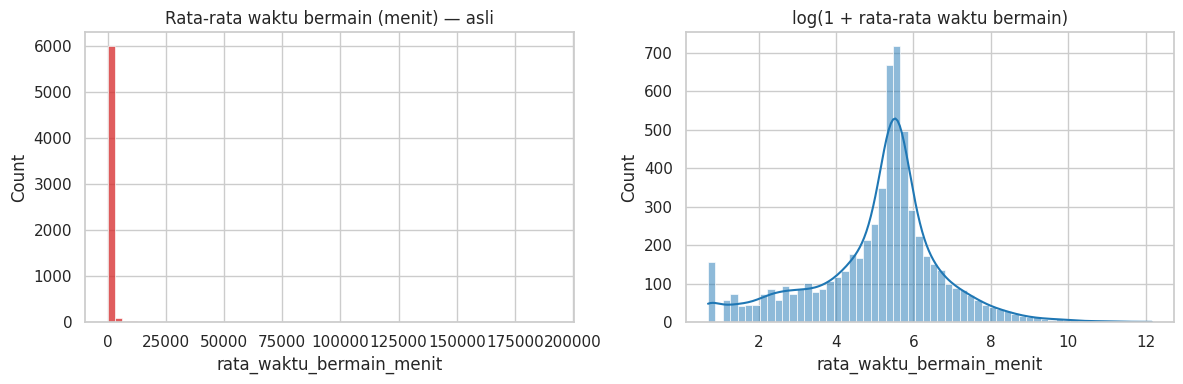

In [ ]:
print(data[TARGET].describe().round(1))
print('Skewness asli :', round(data[TARGET].skew(), 2))
print('Skewness log  :', round(np.log1p(data[TARGET]).skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data[TARGET], bins=60, ax=ax[0], color='tab:red')
ax[0].set_title('Rata-rata waktu bermain (menit) — asli')
sns.histplot(np.log1p(data[TARGET]), bins=60, ax=ax[1], color='tab:blue', kde=True)
ax[1].set_title('log(1 + rata-rata waktu bermain)')
plt.tight_layout(); plt.show()

Fitur dengan rentang sangat lebar (jumlah ulasan, jumlah achievement, harga) juga di-log supaya model linear tidak didominasi nilai ekstrem. Untuk Random Forest sebenarnya tidak wajib, tapi tidak merugikan.

In [ ]:
LOG_FITUR = ['ulasan_positif', 'ulasan_negatif', 'jumlah_achievement', 'harga_gbp']
for c in LOG_FITUR:
    X[c] = np.log1p(X[c])

y = np.log1p(data[TARGET])   # target dalam skala log
y_menit = data[TARGET]       # target asli (menit), untuk interpretasi

## 4. Split Data Train / Test (80 : 20)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (4936, 31) | Test: (1234, 31)


## 5. Perbandingan Model (5-Fold Cross Validation di data train)
| Model | Alasan dipakai |
|---|---|
| Baseline (tebak rata-rata) | Patokan minimum; model lain harus lebih baik dari ini |
| Linear Regression | Paling mudah diinterpretasi, nyambung dengan materi regresi di statistika |
| Random Forest | Menangkap hubungan non-linear & interaksi antar fitur |
| Gradient Boosting | Model ensemble yang biasanya kuat untuk data tabel |

Metrik: **R²** (proporsi variasi yang dijelaskan model, makin dekat 1 makin baik), **MAE** dan **RMSE** (rata-rata kesalahan, dalam skala log, makin kecil makin baik).

In [ ]:
models = {
    'Baseline (rata-rata)': DummyRegressor(strategy='mean'),
    'Linear Regression':    make_pipeline(StandardScaler(), LinearRegression()),
    'Random Forest':        RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE),
    'Gradient Boosting':    HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=RANDOM_STATE),
}
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
hasil = []
for nama, m in models.items():
    cv = cross_validate(m, X_train, y_train, cv=kf,
                        scoring=['r2', 'neg_mean_absolute_error', 'neg_root_mean_squared_error'])
    hasil.append({'Model': nama,
                  'R2 (rata2)': cv['test_r2'].mean(), 'R2 (std)': cv['test_r2'].std(),
                  'MAE log': -cv['test_neg_mean_absolute_error'].mean(),
                  'RMSE log': -cv['test_neg_root_mean_squared_error'].mean()})
hasil_cv = pd.DataFrame(hasil).set_index('Model').round(3)
hasil_cv

,R2 (rata2),R2 (std),MAE log,RMSE log
Model,,,,
Baseline (rata-rata),-0.000,0.000,1.218,1.664
Linear Regression,0.299,0.028,1.040,1.392
Random Forest,0.370,0.021,0.915,1.321
Gradient Boosting,0.346,0.021,0.940,1.345


## 6. Tuning Hyperparameter Random Forest (GridSearchCV)

In [ ]:
param_grid = {
    'n_estimators': [300],
    'min_samples_leaf': [2, 5, 10],
    'max_features': [0.33, 0.5, 1.0],
}
grid = GridSearchCV(RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE),
                    param_grid, cv=kf, scoring='r2')
grid.fit(X_train, y_train)
print('Parameter terbaik :', grid.best_params_)
print('R2 CV terbaik     :', round(grid.best_score_, 3))
best_rf = grid.best_estimator_

Parameter terbaik : {'max_features': 0.33, 'min_samples_leaf': 5, 'n_estimators': 300}
R2 CV terbaik     : 0.384


## 7. Evaluasi Akhir di Data Test

In [ ]:
def evaluasi(model, nama):
    pred_log = model.predict(X_test)
    pred_menit = np.expm1(pred_log)
    asli_menit = np.expm1(y_test)
    return {'Model': nama,
            'R2 (log)': r2_score(y_test, pred_log),
            'MAE (log)': mean_absolute_error(y_test, pred_log),
            'RMSE (log)': np.sqrt(mean_squared_error(y_test, pred_log)),
            'Median error (menit)': np.median(np.abs(asli_menit - pred_menit))}

lr = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
gb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=RANDOM_STATE).fit(X_train, y_train)
base = DummyRegressor().fit(X_train, y_train)

hasil_test = pd.DataFrame([evaluasi(base, 'Baseline (rata-rata)'),
                           evaluasi(lr, 'Linear Regression'),
                           evaluasi(gb, 'Gradient Boosting'),
                           evaluasi(best_rf, 'Random Forest (tuned)')]).set_index('Model').round(3)
hasil_test

,R2 (log),MAE (log),RMSE (log),Median error (menit)
Model,,,,
Baseline (rata-rata),-0.004,1.293,1.758,135.708
Linear Regression,0.285,1.084,1.483,110.796
Gradient Boosting,0.365,0.965,1.398,96.996
Random Forest (tuned),0.383,0.947,1.378,89.055


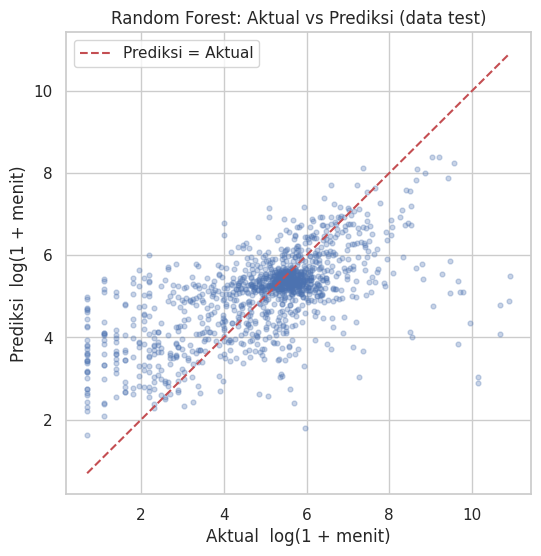

In [ ]:
pred = best_rf.predict(X_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.3, s=12)
lim = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
plt.plot(lim, lim, 'r--', label='Prediksi = Aktual')
plt.xlabel('Aktual  log(1 + menit)'); plt.ylabel('Prediksi  log(1 + menit)')
plt.title('Random Forest: Aktual vs Prediksi (data test)')
plt.legend(); plt.show()

## 8. Faktor Paling Berpengaruh (Feature Importance)
Dipakai **Permutation Importance** pada data test: setiap fitur diacak satu per satu, lalu dilihat seberapa besar R² model turun. Makin besar penurunannya → makin penting fitur itu. Cara ini lebih jujur dibanding importance bawaan Random Forest (yang bias ke fitur dengan banyak nilai unik).

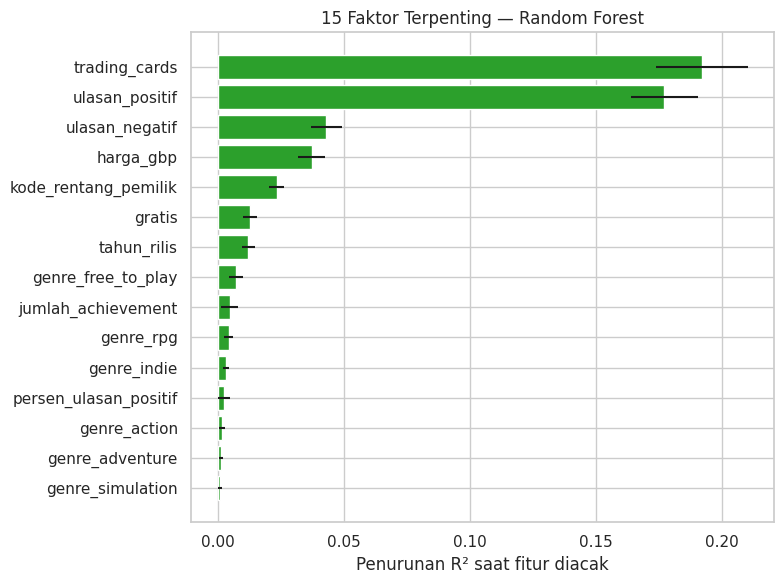

,fitur,penurunan_R2,std
0,trading_cards,0.1919,0.0182
1,ulasan_positif,0.1771,0.0134
2,ulasan_negatif,0.0431,0.0061
3,harga_gbp,0.0373,0.0054
4,kode_rentang_pemilik,0.0234,0.0029
5,gratis,0.0127,0.0026
6,tahun_rilis,0.0122,0.0026
7,genre_free_to_play,0.0072,0.0027
8,jumlah_achievement,0.0048,0.0034
9,genre_rpg,0.0044,0.0018


In [ ]:
perm = permutation_importance(best_rf, X_test, y_test, n_repeats=15, random_state=RANDOM_STATE, scoring='r2')
imp = (pd.DataFrame({'fitur': X.columns, 'penurunan_R2': perm.importances_mean, 'std': perm.importances_std})
         .sort_values('penurunan_R2', ascending=False).reset_index(drop=True))

top = imp.head(15)
plt.figure(figsize=(8, 6))
plt.barh(top['fitur'][::-1], top['penurunan_R2'][::-1], xerr=top['std'][::-1], color='tab:green')
plt.xlabel('Penurunan R² saat fitur diacak'); plt.title('15 Faktor Terpenting — Random Forest')
plt.tight_layout(); plt.show()
imp.head(15).round(4)

**Arah pengaruh (naik atau turun?).** Permutation importance hanya bilang *seberapa penting*, bukan *arahnya*. Untuk arah, dipakai koefisien Linear Regression yang fiturnya sudah distandarisasi: koefisien **positif** = makin besar fitur → waktu bermain cenderung makin lama, **negatif** = sebaliknya.

In [ ]:
coef = pd.Series(lr.named_steps['linearregression'].coef_, index=X.columns)
arah = (pd.DataFrame({'koefisien_std': coef})
          .assign(arah=lambda d: np.where(d.koefisien_std > 0, 'naik (+)', 'turun (-)'))
          .loc[imp['fitur']])   # urut sesuai tingkat kepentingan
arah.head(15).round(3)

,koefisien_std,arah
trading_cards,0.493,naik (+)
ulasan_positif,0.520,naik (+)
ulasan_negatif,-0.166,turun (-)
harga_gbp,0.163,naik (+)
kode_rentang_pemilik,0.401,naik (+)
gratis,-0.191,turun (-)
tahun_rilis,0.155,naik (+)
genre_free_to_play,-0.102,turun (-)
jumlah_achievement,0.028,naik (+)
genre_rpg,0.088,naik (+)


### Fokus ke variabel utama Kelompok 8
Rumusan masalah 3 menyebut **jumlah pemilik, jumlah achievement, dan mode permainan (single/multi player)**, dan variabel utama di kerangka juga mencakup **harga game**. Berikut posisi variabel-variabel tersebut:

In [ ]:
fokus = ['kode_rentang_pemilik', 'jumlah_achievement', 'harga_gbp', 'single_player', 'multi_player']
tabel_fokus = imp.set_index('fitur').loc[fokus, ['penurunan_R2']]
tabel_fokus['peringkat'] = [imp.index[imp['fitur'] == f][0] + 1 for f in fokus]
tabel_fokus['arah (Linear Reg.)'] = arah.loc[fokus, 'arah']
tabel_fokus.round(4)

,penurunan_R2,peringkat,arah (Linear Reg.)
fitur,,,
kode_rentang_pemilik,0.0234,5,naik (+)
jumlah_achievement,0.0048,9,naik (+)
harga_gbp,0.0373,4,naik (+)
single_player,0.0000,27,turun (-)
multi_player,0.0010,16,naik (+)


In [ ]:
# Rata-rata & median waktu bermain berdasarkan mode permainan (menit) — pelengkap interpretasi
for kol in ['single_player', 'multi_player']:
    print(data.groupby(kol)[TARGET].agg(['count', 'median', 'mean']).round(1).rename(index={0:'tidak', 1:'ya'}), '\n')

               count  median    mean
single_player                       
tidak            447   175.0  1443.3
ya              5723   222.0   596.0 

              count  median    mean
multi_player                       
tidak          4706   220.0   548.3
ya             1464   233.5  1007.9 



## 9. (Tambahan) Klasifikasi Kategori Waktu Bermain
Kadang lebih mudah dipresentasikan dalam bentuk kategori. Target dibagi 3 kelas sama banyak (**tertil**): **Rendah / Sedang / Tinggi**. Patokan tebak acak ≈ 33%.

Batas kategori (menit): [1.00000e+00 1.32000e+02 2.92000e+02 1.90625e+05]
rata_waktu_bermain_menit
Rendah    2064
Sedang    2061
Tinggi    2045
Name: count, dtype: int64
Akurasi baseline : 0.335
Akurasi RF       : 0.617
              precision    recall  f1-score   support

      Rendah       0.69      0.66      0.67       413
      Sedang       0.56      0.66      0.61       412
      Tinggi       0.62      0.53      0.57       409

    accuracy                           0.62      1234
   macro avg       0.62      0.62      0.62      1234
weighted avg       0.62      0.62      0.62      1234



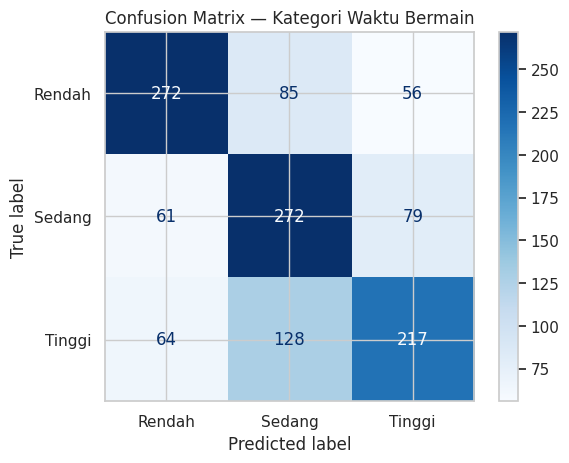

In [ ]:
kategori, batas = pd.qcut(data[TARGET], q=3, labels=['Rendah', 'Sedang', 'Tinggi'], retbins=True)
print('Batas kategori (menit):', np.round(batas, 0))
print(kategori.value_counts())

Xc_train, Xc_test, yc_train, yc_test = train_test_split(X, kategori, test_size=0.2,
                                                        random_state=RANDOM_STATE, stratify=kategori)
clf = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE)
clf.fit(Xc_train, yc_train)
yc_pred = clf.predict(Xc_test)

print('Akurasi baseline :', round(accuracy_score(yc_test, DummyClassifier().fit(Xc_train, yc_train).predict(Xc_test)), 3))
print('Akurasi RF       :', round(accuracy_score(yc_test, yc_pred), 3))
print(classification_report(yc_test, yc_pred))
ConfusionMatrixDisplay.from_predictions(yc_test, yc_pred, labels=['Rendah', 'Sedang', 'Tinggi'], cmap='Blues')
plt.title('Confusion Matrix — Kategori Waktu Bermain'); plt.show()

## 10. Simpan Model & Contoh Prediksi Game Baru

In [ ]:
joblib.dump({'model': best_rf, 'fitur': list(X.columns), 'log_fitur': LOG_FITUR}, 'model_waktu_bermain_rf.pkl')
print('Model tersimpan: model_waktu_bermain_rf.pkl')

def prediksi_waktu_bermain(game: dict) -> float:
    """Input: dict karakteristik game (nilai asli, belum di-log). Output: perkiraan rata-rata waktu bermain (menit)."""
    baris = pd.DataFrame([{k: game.get(k, 0) for k in X.columns}])
    for c in LOG_FITUR:
        baris[c] = np.log1p(baris[c])
    return float(np.expm1(best_rf.predict(baris[X.columns])[0]))

contoh_game = {
    'tahun_rilis': 2018, 'bahasa_inggris': 1, 'batas_usia': 0, 'harga_gbp': 15.99, 'gratis': 0,
    'jumlah_achievement': 40, 'punya_achievement': 1, 'ulasan_positif': 5000, 'ulasan_negatif': 600,
    'persen_ulasan_positif': 89.3, 'kode_rentang_pemilik': 6, 'dukung_mac': 1, 'dukung_linux': 0,
    'jumlah_platform': 2, 'single_player': 1, 'multi_player': 1, 'steam_cloud': 1, 'trading_cards': 1,
    'dukung_controller': 1, 'genre_action': 1, 'genre_rpg': 1, 'jumlah_genre': 2,
}
print(f'Perkiraan rata-rata waktu bermain: {prediksi_waktu_bermain(contoh_game):.0f} menit '
      f'(~{prediksi_waktu_bermain(contoh_game)/60:.1f} jam)')

Model tersimpan: model_waktu_bermain_rf.pkl
Perkiraan rata-rata waktu bermain: 513 menit (~8.5 jam)


## 11. Kesimpulan
1. **Performa model.** Random Forest (tuned) adalah model terbaik dengan **R² ≈ 0,38** di data test (Linear Regression ≈ 0,29; baseline ≈ 0). Artinya karakteristik game menjelaskan sekitar 38% variasi rata-rata waktu bermain (skala log). Sisanya dipengaruhi hal yang tidak ada di dataset (kualitas gameplay, komunitas, update, dll). Untuk data perilaku pemain seperti ini, R² di kisaran 0,3–0,4 itu wajar.
2. **Faktor paling berpengaruh:** `trading_cards`, `ulasan_positif`, `ulasan_negatif`, `harga_gbp`, dan `kode_rentang_pemilik` (jumlah pemilik). Game yang punya trading cards, lebih banyak ulasan, lebih mahal, dan pemiliknya lebih banyak cenderung punya rata-rata waktu bermain lebih lama. Game gratis cenderung lebih rendah.
3. **Variabel utama kelompok:** harga (peringkat 4) dan jumlah pemilik (peringkat 5) cukup berpengaruh; **jumlah achievement** pengaruhnya kecil (peringkat 9); **mode permainan** (single/multi player) hampir tidak menambah daya prediksi. Hasil ini bisa dibandingkan dengan hasil uji hipotesis di RM 3.
4. **Klasifikasi** kategori Rendah/Sedang/Tinggi mencapai akurasi **≈ 62%**, hampir 2× tebak acak (33%).

**Catatan interpretasi (penting saat presentasi):**
- Ini **hubungan, bukan sebab-akibat**. Contoh: ulasan banyak bisa jadi *akibat* game sering dimainkan, bukan penyebabnya.
- `trading_cards` kemungkinan menaikkan waktu bermain karena pemain sering membiarkan game terbuka (idle) untuk mendapatkan kartu.
- Arah koefisien `ulasan_negatif` bernilai negatif karena dibaca *setelah* mengontrol `ulasan_positif` (kedua variabel saling berkorelasi kuat).
- Model hanya berlaku untuk game yang waktu bermainnya tercatat (6.170 game).